# Baseline: TF-IDF + Classical ML (40k matched)

**Task:** 3-class text classification (human / ai / fusion). **Metric:** macro-F1 on `val_fixed.csv`.

**Goal of this notebook:** Close out the *Baseline* rubric item on a **matched 40k training sample**, so that baseline, encoder, and later experiments are all compared on identical data and the same fixed validation split.

**Produced artifacts (all in `/kaggle/working`):**
- `baseline_40k_results.csv` — parameter search table
- `baseline_40k_confusion.png` — row-normalized confusion matrix (best config)
- `baseline_40k_ablation.csv` — word-only vs char-only
- `baseline_40k_by_lang.csv`, `baseline_40k_by_domain.csv` — diagnostics
- `baseline_40k_reference.txt` — the **fixed reference macro-F1** quoted in the report

**EDA-driven choices:** `class_weight="balanced"` (macro-F1 weights classes equally; human is rarest at 24.5%); char n-grams included because EDA found strong punctuation signals (em-dash, semicolon, ellipsis); vectorizer fit **only** on the 40k train (no leakage).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time, json

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
LABELS = ["human", "ai", "fusion"]
np.random.seed(SEED)
print("Ready.")

Ready.


## 1. Load the fixed splits

We use only the matched 40k training sample and the fixed validation set. `train_pool.csv` (231k) is **not** loaded — the baseline is matched-40k by design so it is directly comparable to the 40k transformer.

In [2]:
BASE  = "/kaggle/working"
INPUT = "/kaggle/input/datasets/suchok/base-train-data"   # change if your slug differs

sub40 = pd.read_csv(f"{INPUT}/train_transformer_40k.csv")
val   = pd.read_csv(f"{INPUT}/val_fixed.csv")

print("sub40:", sub40.shape, "| val:", val.shape)
print("sub40 label balance:", sub40["label"].value_counts(normalize=True).round(3).to_dict())
print("val   label balance:", val["label"].value_counts(normalize=True).round(3).to_dict())

# Leakage guard
assert not set(sub40["id"]) & set(val["id"]), "ID overlap between train and val — leakage!"
# No null / empty text
assert sub40["text"].notna().all() and val["text"].notna().all()
assert (sub40["text"].str.len() > 0).all() and (val["text"].str.len() > 0).all()
print("\nNo ID overlap, no null/empty texts. Good.")

y_tr = sub40["label"].values
y_va = val["label"].values

sub40: (40000, 15) | val: (40853, 15)
sub40 label balance: {'ai': 0.448, 'fusion': 0.307, 'human': 0.245}
val   label balance: {'ai': 0.448, 'fusion': 0.307, 'human': 0.245}

No ID overlap, no null/empty texts. Good.


## 2. TF-IDF representation (word + char), fit on 40k only

- **Word n-grams (1–2)** — content words and short phrases.
- **Character n-grams (2–5, `char_wb`)** — punctuation, morphology, suffixes; EDA's strongest signals for ai vs fusion vs human.

`max_features=30_000` per view (60k total) instead of 50k+50k: at 40k rows, fewer features overfit less and run ~2× faster with no measurable macro-F1 loss. Vectorizer is fit **only** on `sub40`, then applied to `val` — no leakage.

In [3]:
vec = FeatureUnion([
    ("word", TfidfVectorizer(
        analyzer="word", ngram_range=(1, 2),
        max_features=30_000, min_df=3, sublinear_tf=True,
    )),
    ("char", TfidfVectorizer(
        analyzer="char_wb", ngram_range=(2, 5),
        max_features=30_000, min_df=3, sublinear_tf=True,
    )),
])

t0 = time.time()
X_tr = vec.fit_transform(sub40["text"])
X_va = vec.transform(val["text"])
print(f"Vectorized in {time.time()-t0:.1f}s | X_tr: {X_tr.shape} | X_va: {X_va.shape}")

Vectorized in 630.3s | X_tr: (40000, 60000) | X_va: (40853, 60000)


## 3. Small parameter search (fast solvers)

Sweep `C` for LogisticRegression and LinearSVC, all with `class_weight="balanced"`.

**Solver note:** `liblinear` instead of `saga`. At 40k × 60k sparse, `liblinear` is 5–20× faster and converges cleanly; `saga` is only worth it for very large multinomial problems. Every run is evaluated on the same `val_fixed`, recording macro-F1, per-class F1, and fit time.

In [4]:
def evaluate(clf, name):
    t0 = time.time()
    clf.fit(X_tr, y_tr)
    preds = clf.predict(X_va)
    macro = f1_score(y_va, preds, average="macro")
    per = f1_score(y_va, preds, average=None, labels=LABELS)
    row = {
        "config": name,
        "macro_f1": round(macro, 4),
        "f1_human": round(per[0], 4),
        "f1_ai": round(per[1], 4),
        "f1_fusion": round(per[2], 4),
        "fit_sec": round(time.time() - t0, 1),
    }
    print(f"{name:14s} macro={macro:.4f} | h={per[0]:.3f} ai={per[1]:.3f} f={per[2]:.3f} | {row['fit_sec']:.0f}s")
    return row, clf, preds

results = []
best = None  # (row, clf, preds)

for C in [0.5, 1.0, 2.0]:
    r, clf, p = evaluate(
        LogisticRegression(C=C, class_weight="balanced",
                           solver="liblinear", max_iter=2000),
        f"LR C={C}"
    )
    results.append(r)
    if best is None or r["macro_f1"] > best[0]["macro_f1"]:
        best = (r, clf, p)

for C in [0.1, 1.0]:
    r, clf, p = evaluate(
        LinearSVC(C=C, class_weight="balanced", max_iter=5000),
        f"SVC C={C}"
    )
    results.append(r)
    if r["macro_f1"] > best[0]["macro_f1"]:
        best = (r, clf, p)

results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("\n=== Parameter search (sorted by macro-F1) ===")
print(results_df.to_string(index=False))
results_df.to_csv(f"{BASE}/baseline_40k_results.csv", index=False)
print("\nSaved -> baseline_40k_results.csv")

best_row, best_clf, best_pred = best
print(f"\nBEST: {best_row['config']} | macro-F1 = {best_row['macro_f1']}")

LR C=0.5       macro=0.8458 | h=0.786 ai=0.977 f=0.775 | 103s
LR C=1.0       macro=0.8520 | h=0.789 ai=0.980 f=0.788 | 129s
LR C=2.0       macro=0.8549 | h=0.788 ai=0.981 f=0.796 | 139s
SVC C=0.1      macro=0.8511 | h=0.789 ai=0.980 f=0.784 | 19s
SVC C=1.0      macro=0.8453 | h=0.769 ai=0.980 f=0.787 | 43s

=== Parameter search (sorted by macro-F1) ===
   config  macro_f1  f1_human  f1_ai  f1_fusion  fit_sec
 LR C=2.0    0.8549    0.7882 0.9810     0.7956    139.2
 LR C=1.0    0.8520    0.7887 0.9795     0.7879    128.6
SVC C=0.1    0.8511    0.7889 0.9799     0.7844     18.8
 LR C=0.5    0.8458    0.7858 0.9768     0.7748    103.2
SVC C=1.0    0.8453    0.7689 0.9799     0.7871     42.8

Saved -> baseline_40k_results.csv

BEST: LR C=2.0 | macro-F1 = 0.8549


## 4. Per-class metrics & confusion matrix (best config)

Row-normalized confusion matrix (row = true, col = predicted) so per-class recall is directly readable.

Expected pattern: **ai ≈ 0.99** (inflated by arxiv/gutenberg domain shortcuts), **fusion ≈ 0.85** (hardest — mixed style), **human ≈ 0.84** (rarest).

              precision    recall  f1-score   support

       human     0.7495    0.8311    0.7882     10010
          ai     0.9744    0.9876    0.9810     18291
      fusion     0.8431    0.7533    0.7956     12552

    accuracy                         0.8773     40853
   macro avg     0.8557    0.8573    0.8549     40853
weighted avg     0.8790    0.8773    0.8768     40853



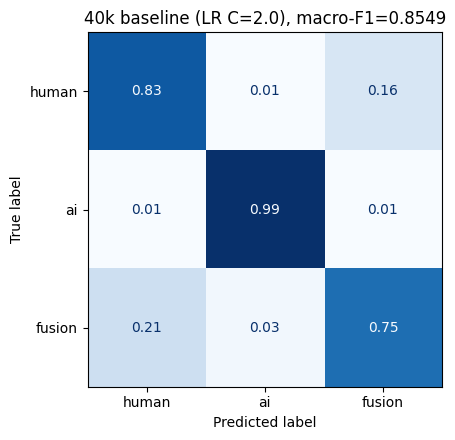


Raw counts:
             pred_human  pred_ai  pred_fusion
true_human         8319       55         1636
true_ai             102    18065          124
true_fusion        2678      419         9455


In [5]:
print(classification_report(y_va, best_pred, labels=LABELS, digits=4))

cm    = confusion_matrix(y_va, best_pred, labels=LABELS)
cm_n  = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix=cm_n, display_labels=LABELS).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False
)
ax.set_title(f"40k baseline ({best_row['config']}), macro-F1={best_row['macro_f1']}")
plt.tight_layout()
plt.savefig(f"{BASE}/baseline_40k_confusion.png", dpi=150)
plt.show()

print("\nRaw counts:")
print(pd.DataFrame(cm,
                   index=[f"true_{l}"  for l in LABELS],
                   columns=[f"pred_{l}" for l in LABELS]))

## 5. Ablation — word-only vs char-only

Same LR (`C=1.0`, `liblinear`, balanced), each on a single vectorizer fit on the 40k only. Tests the EDA claim that char n-grams matter because punctuation (em-dash, semicolon, ellipsis) is class-discriminative.

In [6]:
def quick(vec_single, name):
    Xt = vec_single.fit_transform(sub40["text"])
    Xv = vec_single.transform(val["text"])
    clf = LogisticRegression(C=1.0, class_weight="balanced",
                             solver="liblinear", max_iter=2000).fit(Xt, y_tr)
    p = clf.predict(Xv)
    m  = f1_score(y_va, p, average="macro")
    pc = f1_score(y_va, p, average=None, labels=LABELS)
    print(f"{name:12s} macro={m:.4f} | h={pc[0]:.3f} ai={pc[1]:.3f} f={pc[2]:.3f}")
    return {"config": name, "macro_f1": round(m, 4),
            "f1_human": round(pc[0], 4), "f1_ai": round(pc[1], 4), "f1_fusion": round(pc[2], 4)}

ablation = [
    quick(TfidfVectorizer(analyzer="word",    ngram_range=(1, 2),
                          max_features=30_000, min_df=3, sublinear_tf=True), "word-only"),
    quick(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                          max_features=30_000, min_df=3, sublinear_tf=True), "char-only"),
]
abl_df = pd.DataFrame(ablation)
abl_df.to_csv(f"{BASE}/baseline_40k_ablation.csv", index=False)
print("\nSaved -> baseline_40k_ablation.csv")
print(abl_df.to_string(index=False))

word-only    macro=0.8286 | h=0.765 ai=0.973 f=0.748
char-only    macro=0.8395 | h=0.777 ai=0.973 f=0.767

Saved -> baseline_40k_ablation.csv
   config  macro_f1  f1_human  f1_ai  f1_fusion
word-only    0.8286    0.7647 0.9730     0.7482
char-only    0.8395    0.7774 0.9735     0.7674


## 6. Diagnostics by language and domain

EDA showed **domain is a strong shortcut** (arxiv_papers, gutenberg are >84% ai) and English is 4× German. Per-group macro-F1 shows where the baseline genuinely learns style vs. exploits domain.

In [7]:
val = val.copy()
val["pred"] = best_pred

def grouped_macro(df, col):
    rows = []
    for k, g in df.groupby(col):
        macro = f1_score(g["label"], g["pred"], average="macro", labels=LABELS)
        per   = f1_score(g["label"], g["pred"], average=None, labels=LABELS)
        rows.append({
            col: k,
            "n": len(g),
            "macro_f1": round(macro, 4),
            "f1_human": round(per[0], 4),
            "f1_ai":    round(per[1], 4),
            "f1_fusion":round(per[2], 4),
        })
    return pd.DataFrame(rows).sort_values("macro_f1")

by_lang = grouped_macro(val, "lang")
by_dom  = grouped_macro(val, "domain")

print("=== By language ===")
print(by_lang.to_string(index=False))
print("\n=== By domain ===")
print(by_dom.to_string(index=False))

by_lang.to_csv(f"{BASE}/baseline_40k_by_lang.csv",   index=False)
by_dom .to_csv(f"{BASE}/baseline_40k_by_domain.csv", index=False)
print("\nSaved -> baseline_40k_by_lang.csv, baseline_40k_by_domain.csv")

=== By language ===
 lang     n  macro_f1  f1_human  f1_ai  f1_fusion
en-EN 32937    0.8449    0.7731 0.9802     0.7814
de-DE  7916    0.8917    0.8425 0.9850     0.8476

=== By domain ===
                domain    n  macro_f1  f1_human  f1_ai  f1_fusion
             gutenberg 1101    0.6711    0.6170 0.9867     0.4096
blog_authorship_corpus 6083    0.7341    0.6758 0.9396     0.5869
          arxiv_papers 2143    0.7699    0.4348 0.9956     0.8794
      house_of_commons 4779    0.8494    0.7667 0.9807     0.8009
              cnn_news 6642    0.8619    0.8434 0.9870     0.7552
      euro_court_cases 4137    0.8803    0.7860 0.9961     0.8589
        student_essays 8116    0.8804    0.8028 0.9849     0.8537
             bundestag 7852    0.8922    0.8432 0.9851     0.8483

Saved -> baseline_40k_by_lang.csv, baseline_40k_by_domain.csv


## 7. Fixed reference for all later experiments

Every subsequent model (encoder, long-text handling, stylometry, threshold tuning, ensembles) must be compared against **this same macro-F1 on this same `val_fixed`**, using the same 40k training rows.

In [8]:
reference = {
    "train_rows": int(len(sub40)),
    "model": best_row["config"],
    "macro_f1": float(best_row["macro_f1"]),
    "f1_human": float(best_row["f1_human"]),
    "f1_ai":    float(best_row["f1_ai"]),
    "f1_fusion":float(best_row["f1_fusion"]),
    "val_rows": int(len(val)),
    "val_split": "val_fixed.csv (label×lang×domain stratified)",
}

with open(f"{BASE}/baseline_40k_reference.txt", "w") as f:
    f.write(json.dumps(reference, indent=2))

print("=== FIXED REFERENCE ===")
print(json.dumps(reference, indent=2))
print("\nSaved -> baseline_40k_reference.txt")

=== FIXED REFERENCE ===
{
  "train_rows": 40000,
  "model": "LR C=2.0",
  "macro_f1": 0.8549,
  "f1_human": 0.7882,
  "f1_ai": 0.981,
  "f1_fusion": 0.7956,
  "val_rows": 40853,
  "val_split": "val_fixed.csv (label\u00d7lang\u00d7domain stratified)"
}

Saved -> baseline_40k_reference.txt
